### Calculate QA & VQA Accuracy


In [2]:
import json
import os

dataset = "infoseek"
model_ckpt = "pixar-13b_kld_0.1_focal_tversky_8_pixar_ft_info_tok_padmask_lr_3e-4_gt_interleaved"
OUT_PATH = f"/home/jeonghkim/projects/pixar/pixar/src/results/{dataset}/{model_ckpt}/predictions_infoseek_val_gpt-4o_False_temp_recalc.jsonl"

In [6]:
with open(OUT_PATH, 'r') as reader:
    em_acc = 0.0
    llm_acc = 0.0
    instances = []
    for line in reader:
        instance = json.loads(line)
        em_acc += instance['accuracy']
        llm_acc += instance['llm_score']
        instances.append(instance)

print(f"Number of instances in [ {dataset} ] : {len(instances)}")
print(f"EM : {em_acc / len(instances)}")
print(f"LLM Acc. : {llm_acc / len(instances)}")

Number of instances in [ infoseek ] : 1000
EM : 0.112
LLM Acc. : 0.17


In [4]:
instance['llm_score']

{'image_path': '/home/jeonghkim/projects/pixar/data/infoseek/images/oven_04959443.jpg',
 'output_text': "<s> A chat between a curious human and an artificial intelligence assistant. The assistant gives helpful, detailed, and polite answers to the human's questions.###Human: <im_start><unk><im_end> \nWhich country does this food come from?###region:Mexico</s>",
 'ground_truth_text': ['Portugal', 'France'],
 'accuracy': 0.0,
 'llm_score': 1.0,
 'llm_reason': 'The food shown is churros, which are traditionally associated with Mexico, making the answer correct despite the ground truth listing Portugal and France.'}

### Calculate the <search> token stat for the model outputs


In [3]:
import json
import os

dataset = "hotpotqa"
model_ckpt = "pixar-13b_kld_0.1_focal_tversky_8_pixar_ft_info_tok_padmask_lr_3e-4_gt_interleaved"
fpath = f"/home/jeonghkim/projects/pixar/pixar/src/results/{dataset}/{model_ckpt}/predictions_hotpotqa_val_gpt-4o_False_search.jsonl"

In [4]:
with open(fpath, "r") as reader:
    # TODO: count the # of <region> tokens in the presence of <search> tokens (total vs. ones that got acc = 1.0)
    search_cnt = 0
    region_cnt = 0
    img_cnt = 0
    text_cnt = 0
    for line in reader:
        d = json.loads(line)
        if "<search>" in d["output_text"]:
            search_cnt += 1
            if "<region>" in d["output_text"]:
                region_cnt += 1
            if "<img>" in d["output_text"]:
                img_cnt += 1
            if "<region>" not in d["output_text"] and "<igm>" not in d["output_text"]:
                text_cnt += 1

    print(f"Total <search> count: {search_cnt}")
    print(f"<region> count: {region_cnt}")
    print(f"<img> count: {img_cnt}")
    print(f"<text> count: {text_cnt}")

Total <search> count: 106
<region> count: 95
<img> count: 5
<text> count: 11


### Dataset Viewer

- View data points for manual inspection


In [1]:
# Jupyter-ready helper to visualize a JSONL VQA/RAG sample with image, Q/A fields,
# search calls, ground-truth answers, and retrieved instances.
#
# How to use (two options):
# 1) Point to your JSONL file and pick an index:
#       jsonl_path = "/path/to/your/file.jsonl"
#       data = load_jsonl(jsonl_path)
#       render_record(data[0])   # or any index
#
# 2) Paste a raw JSONL line (as a string) and visualize it:
#       raw = '''{"id": "...", ... }'''
#       record = json.loads(raw)
#       render_record(record)
#
# Notes:
# - Images are shown with a max width so they fit inside the notebook panel.
# - Missing files/fields are handled gracefully with clear messages.
# - Retrieved items and search calls are organized into compact tables.
# - If available, region-crop/mask overlay images from `mask_path` are shown.

from __future__ import annotations
import os, io, json, textwrap, html
from typing import List, Dict, Any, Optional
from PIL import Image
import pandas as pd
from IPython.display import display, HTML
from base64 import b64encode

# ---------- Utilities ----------

def load_jsonl(path: str) -> List[Dict[str, Any]]:
    """Load a JSONL file into a list of dicts."""
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as e:
                print(f"[WARN] Skipping invalid JSON line: {e}")
    return rows

def _img_to_data_url(pil_img: Image.Image, max_width: int = 420) -> str:
    """Convert PIL image to a base64 data URL, resizing to fit max_width."""
    w, h = pil_img.size
    if w > max_width:
        ratio = max_width / float(w)
        pil_img = pil_img.resize((int(w * ratio), int(h * ratio)))
    buf = io.BytesIO()
    pil_img.save(buf, format="PNG")
    return "data:image/png;base64," + b64encode(buf.getvalue()).decode("ascii")

def _path_to_data_url(path: str, max_width: int = 420) -> Optional[str]:
    """Load an image from disk and convert to a base64 data URL; returns None if not found."""
    if not path or not os.path.exists(path):
        return None
    try:
        img = Image.open(path).convert("RGBA")
        return _img_to_data_url(img, max_width=max_width)
    except Exception as e:
        print(f"[WARN] Could not open image: {path} ({e})")
        return None

def _wrap(s: Any, width: int = 120) -> str:
    """Nicely wrap long text for table cells."""
    if s is None:
        return ""
    if not isinstance(s, str):
        s = json.dumps(s, ensure_ascii=False)
    s = s.strip()
    return "\n".join(textwrap.wrap(s, width=width)) if len(s) > width else s

def _hl_tags(text: str) -> str:
    """Highlight <search>, <region>, <information> tags in an HTML-safe way."""
    if text is None:
        return ""
    esc = html.escape(text)
    # lightweight tag highlighting
    esc = esc.replace("&lt;search&gt;", "<span class='tag'>&lt;search&gt;</span>")
    esc = esc.replace("&lt;/search&gt;", "<span class='tag'>&lt;/search&gt;</span>")
    esc = esc.replace("&lt;region&gt;", "<span class='tag region'>&lt;region&gt;</span>")
    esc = esc.replace("&lt;/region&gt;", "<span class='tag region'>&lt;/region&gt;</span>")
    esc = esc.replace("&lt;information&gt;", "<span class='tag info'>&lt;information&gt;</span>")
    esc = esc.replace("&lt;/information&gt;", "<span class='tag info'>&lt;/information&gt;</span>")
    return esc

def _match_ground_truth(answer: str, ground_truth: List[str]) -> Dict[str, bool]:
    """Case-insensitive containment checks for each GT in the answer string."""
    found = {}
    a = (answer or "").lower()
    for gt in ground_truth or []:
        if not isinstance(gt, dict):
            found[gt] = (gt.lower() in a)
    return found

def _df_style(df: pd.DataFrame) -> str:
    """Render a compact HTML table for DataFrames."""
    if df.empty:
        return "<div class='empty'>No items</div>"
    # Escape cells and convert to HTML
    df = df.applymap(lambda x: html.escape(str(x)) if not pd.isna(x) else "")
    return df.to_html(escape=False, index=False)

def _css() -> str:
    return """
<style>
.vqa-card { font-family: ui-sans-serif, system-ui, -apple-system, "Segoe UI", Roboto, "Helvetica Neue", Arial; line-height: 1.35; }
.vqa-grid { display: grid; grid-template-columns: 1fr 1fr; gap: 14px; }
.vqa-row { margin: 6px 0 10px; }
h2 { margin: 6px 0 6px; font-size: 18px; }
h3 { margin: 8px 0 6px; font-size: 15px; }
.block { background: #fafafa; border: 1px solid #eee; border-radius: 8px; padding: 10px 12px; }
.kv { display: grid; grid-template-columns: 140px 1fr; gap: 8px; }
.kv .key { color: #555; font-weight: 600; }
.kv .val { white-space: pre-wrap; }
.code { font-family: ui-monospace, SFMono-Regular, Menlo, Monaco, Consolas, "Liberation Mono", monospace; font-size: 12px; }
.tag { background: #fff3cd; padding: 0 4px; border-radius: 4px; }
.tag.region { background: #e0f7fa; }
.tag.info { background: #e8f5e9; }
.small { font-size: 12px; color: #000; }
img.thumb { border-radius: 8px; border: 1px solid #eee; }
hr.sep { border: none; border-top: 1px solid #eee; margin: 10px 0; }
.table-wrap { overflow-x: auto; }
.empty { color: #888; font-style: italic; }
.badge { display:inline-block; padding:2px 6px; border-radius:6px; background:#eef; border:1px solid #dde; font-size:12px; margin-right:6px;}
.gt-ok { background:#e8f5e9; border-color:#c8e6c9; }
.gt-miss { background:#ffebee; border-color:#ffcdd2; }
.thumb-grid { display:flex; gap:10px; flex-wrap:wrap; }
.thumb-grid figure { margin:0; }
.thumb-grid figcaption { font-size: 12px; color:#555; text-align:center; margin-top:4px; }
</style>
"""

def render_record(rec: Dict[str, Any]) -> None:
    """Visualize a single JSONL VQA/region-RAG record."""
    # Core fields
    rid = rec.get("id", "")
    dataset = rec.get("dataset", "")
    q = rec.get("question", "")
    ans = rec.get("answer", "")
    ans_draft = rec.get("answer_draft", "")
    needs_retrieval = rec.get("needs_retrieval", False)
    rationale = rec.get("needs_rationale", "")
    decomp_qs = rec.get("decomposed_questions", [])
    decomp_needs = rec.get("decomposed_needs_retrieval", [])
    decomp_rat = rec.get("decomposed_rationale", "")
    ground_truth = rec.get("ground_truth", []) or rec.get("ground_truths", [])
    image_paths = rec.get("image_path", []) or rec.get("image_paths", [])
    search_calls = rec.get("search_calls", [])
    retrieved = rec.get("retrieved", {})
    info_offsets = rec.get("info_offsets", [])

    # Pre-compute image thumbnails
    thumbs = []
    for p in image_paths:
        data_url = _path_to_data_url(p, max_width=420)
        thumbs.append((p, data_url))

    # Region/mask overlay previews if available
    region_thumbs = []
    if search_calls:
        # We only check the first call's mask_path entries (extend as needed)
        first_call = search_calls[0]
        mask_paths = first_call.get("mask_path", [])
        for i, mp in enumerate(mask_paths):
            for k in ("bbox", "mask"):
                path = mp.get(k)
                if path:
                    data_url = _path_to_data_url(path, max_width=350)
                    region_thumbs.append((f"{k}_overlay_{i}", path, data_url))

    # Build search calls table
    sc_rows = []
    for sc in search_calls or []:
        row = dict(
            position=sc.get("position", ""),
            qtype=sc.get("qtype", ""),
            query_text=_wrap(sc.get("query_text", "")),
            qtype_reasoning=_wrap(sc.get("qtype_reasoning", "")),
            region_query_label=_wrap(sc.get("region_query_label", "")),
            region_query_span=_wrap(sc.get("region_query_span", "")),
            region_offsets=str(sc.get("region_query_span_offsets", "")),
            num_masks=len(sc.get("mask", []) or []),
        )
        sc_rows.append(row)
    sc_df = pd.DataFrame(sc_rows, columns=[
        "position","qtype","query_text","qtype_reasoning",
        "region_query_label","region_query_span","region_offsets","num_masks"
    ])

    # Build retrieved table (flatten first list if shaped like {"item":[[...]]})
    items = []
    items_blob = (retrieved or {}).get("item", [])
    if isinstance(items_blob, list) and len(items_blob) > 0 and isinstance(items_blob[0], list):
        items_blob = items_blob[0]
    for it in items_blob or []:
        items.append(dict(
            score=it.get("score",""),
            title=it.get("title",""),
            content=_wrap(it.get("content",""), width=160),
            index_dir=it.get("index_dir",""),
            row=it.get("row",""),
            id=it.get("id",""),
        ))
    ret_df = pd.DataFrame(items, columns=["score","title","content","index_dir","row","id"])

    # Ground-truth matching against final answer
    gt_found = _match_ground_truth(ans, ground_truth) if ground_truth else {}

    # HTML assemble
    parts = []
    parts.append(_css())
    parts.append("<div class='vqa-card'>")

    # Header
    parts.append(f"<h2>Record: <span class='badge'>{html.escape(rid)}</span> "
                 f"<span class='badge'>{html.escape(dataset)}</span></h2>")

    # Top grid: image + key fields
    parts.append("<div class='vqa-grid'>")

    # Left: image(s)
    img_html = []
    if thumbs:
        img_html.append("<div class='block'><h3>Image</h3><div class='thumb-grid'>")
        for i, (path, data_url) in enumerate(thumbs):
            if data_url:
                img_html.append(f"<figure><img class='thumb' src='{data_url}'/>"
                                f"<figcaption>image_path[{i}]<br/><span class='small'>{html.escape(path)}</span></figcaption></figure>")
            else:
                img_html.append(f"<figure><div class='empty'>Missing image</div>"
                                f"<figcaption>image_path[{i}]<br/><span class='small'>{html.escape(path)}</span></figcaption></figure>")
        img_html.append("</div></div>")
    else:
        img_html.append("<div class='block'><h3>Image</h3><div class='empty'>No image paths</div></div>")

    # Region overlays
    if region_thumbs:
        img_html.append("<div class='block'><h3>Region Overlays</h3><div class='thumb-grid'>")
        for label, path, data_url in region_thumbs:
            if data_url:
                img_html.append(f"<figure><img class='thumb' src='{data_url}'/>"
                                f"<figcaption>{html.escape(label)}<br/><span class='small'>{html.escape(path)}</span></figcaption></figure>")
            else:
                img_html.append(f"<figure><div class='empty'>Missing overlay</div>"
                                f"<figcaption>{html.escape(label)}<br/><span class='small'>{html.escape(path)}</span></figcaption></figure>")
        img_html.append("</div></div>")
    parts.append("".join(img_html))

    # Right: key text blocks
    key_html = []
    key_html.append("<div class='block'>")
    key_html.append("<h3>Question</h3>")
    key_html.append(f"<div class='val'>{html.escape(q)}</div>")
    key_html.append("<hr class='sep'/>")
    key_html.append("<h3>Answer (final)</h3>")
    key_html.append(f"<div class='val code'>{_hl_tags(ans)}</div>")
    if ans_draft:
        key_html.append("<hr class='sep'/>")
        key_html.append("<h3>Answer Draft</h3>")
        key_html.append(f"<div class='val code'>{_hl_tags(ans_draft)}</div>")
    if needs_retrieval or rationale:
        key_html.append("<hr class='sep'/>")
        key_html.append("<div class='kv'>")
        key_html.append("<div class='key'>Needs Retrieval</div>")
        key_html.append(f"<div class='val'>{'Yes' if needs_retrieval else 'No'}</div>")
        if rationale:
            key_html.append("<div class='key'>Why</div>")
            key_html.append(f"<div class='val small'>{html.escape(rationale)}</div>")
        key_html.append("</div>")
    key_html.append("</div>")

    # Decomposition
    if decomp_qs or decomp_rat or decomp_needs:
        key_html.append("<div class='block'>")
        key_html.append("<h3>Decomposition</h3>")
        if decomp_qs:
            lis = "".join(f"<li>{html.escape(x)}</li>" for x in decomp_qs)
            key_html.append(f"<div><b>Sub-questions</b><ul>{lis}</ul></div>")
        if decomp_needs:
            lis = "".join(f"<li>{'retrieval' if b else 'no retrieval'}</li>" for b in decomp_needs)
            key_html.append(f"<div><b>Sub-question retrieval needs</b><ul>{lis}</ul></div>")
        if decomp_rat:
            key_html.append(f"<div><b>Rationale</b><div class='small'>{html.escape(decomp_rat)}</div></div>")
        key_html.append("</div>")

    # Ground truth
    if ground_truth:
        key_html.append("<div class='block'>")
        key_html.append("<h3>Ground-Truth Answers</h3>")
        if gt_found:
            chips = []
            for gt, ok in gt_found.items():
                cls = "badge gt-ok" if ok else "badge gt-miss"
                chips.append(f"<span class='{cls}'>{html.escape(gt)}</span>")
            key_html.append("<div>" + " ".join(chips) + "</div>")
        else:
            # no answer to match, just list
            chips = " ".join(f"<span class='badge'>{html.escape(gt)}</span>" for gt in ground_truth)
            key_html.append("<div>" + chips + "</div>")
        if info_offsets:
            key_html.append(f"<div class='small' style='margin-top:6px;'>info_offsets: {html.escape(str(info_offsets))}</div>")
        key_html.append("</div>")

    parts.append("".join(key_html))
    parts.append("</div>")  # end grid

    # Search Calls table
    parts.append("<div class='block'><h3>Search Calls</h3>")
    parts.append("<div class='table-wrap'>")
    parts.append(_df_style(sc_df))
    parts.append("</div></div>")

    # Retrieved items table
    parts.append("<div class='block'><h3>Retrieved Instances</h3>")
    parts.append("<div class='table-wrap'>")
    parts.append(_df_style(ret_df))
    parts.append("</div></div>")

    parts.append("</div>")  # end card

    display(HTML("".join(parts)))

# ---------- Demo with the user's provided JSONL line (will skip images if not present locally) ----------

# raw = r'''{"id": "infoseek-infoseek_train_00000000", "dataset": "infoseek", "image_path": ["/home/jeonghkim/projects/pixar/data/infoseek/images/oven_01963180.JPEG"], "question": "Which place is this animal endemic to?", "needs_retrieval": true, "needs_rationale": "the question asks about the endemic location of the animal shown in the image, which is a giant panda. identifying the animal as a giant panda can be done with common knowledge, but knowing its endemic region (native habitat) requires specific external or encyclopedic knowledge about the species' natural distribution, which is not contained in the image itself. therefore, answering this question correctly requires retrieval of external knowledge.", "answer_draft": "the animal shown in the image is a giant panda. this animal is endemic to <search> the People's Republic of China.", "num_search_toks": 1, "is_decomposed": true, "decomposed_questions": ["what animal is shown in the image?", "where is this animal endemic to?"], "decomposed_rationale": "the question asks about the endemic place of the animal shown, which is a panda. identifying the animal can be done by common knowledge, but determining its endemic place requires external knowledge about the species' natural habitat.", "decomposed_needs_retrieval": [false, true], "mc_choices": [], "ground_truth": ["People's Republic of China", "cn", "People's Republic of China", "China", "Mainland China", "China PR", "PR China", "CHN", "CN", "PRC", "🇨🇳"], "rationales": "", "search_calls": [{"position": 74, "qtype": "REGION", "qtype_reasoning": "The question asks about the endemic place of the animal shown in the image, which is a giant panda. To identify the animal and confirm its endemic location, a region-based search focusing on the animal itself is most effective because it allows us to use the specific object (giant panda) for retrieval and then find relevant information about its endemic region.", "query_text": "giant panda", "mask": [{"size": [224, 224], "counts": "m=2a60`I;[67N2O1O100J6L4L4I7J6L400L4M3M3L4M3M3M3M3K5L4M3H8O1N2N2K5L4E;M3N2N2M3M3N2N2N2N2N2N2N2M3lNVKQO0l0l4O^KKe42_KKc43aKJ`44bKJ`44cKI_45cKJ^45dKG_48U1O1O1O1O1O1O1O100O100O100O1O1000000000000000000001O2N001O2N>BO10000001iMYOSNg0S40000000000O100000000000000000000O100000000O10000000000000000000000001O0000001O00000000001O0000001O000000001O000TNWOaMi0[40SNWOcMi0Z40SNWOcMh0^2XObMi0Z40PNXOhMh0W2YOiMf0X2YOiMf0W2ZOjMe0U2]OkMc0U2[OmMd0S2\\OnMb0S2_OmM`0T2@lM?T2AmM>T2AmM>S2CmM<R2EoM;Q2CQN<o1DRN;o1EQN;n1ESN;m1FRN:n1FRN:l1GUN9j1GWN9i1FXN:g1FZN:e1F\\N;c1C_N=a1C_N>_1CaN>^1BbN`0\\1@dNb0Y1^OhNc0W1]OiNd0YN[OQ21Gj0kM^OZ2JK_15`NL`13`NNa10_N1b1M_N3b1L\\N6e1H[N9f1D[N=f1AZN`0f1_O[Na0f1]OZNd0g1[OXNf0h1YOWNi0j1UOWNk0j1QOXNP1h1nNYNS1h1kNXNV1i1fNWN]1j1^NYNc1h1ZNXNh1i1UNVNn1k1oMTNT2l1kMRNX2o1fMQN[2P2bMQN_2Q2^MoMc2R2YMPNh2R2UMmMm2V2jLnMX3T2`LPNa3g22JVLQMj30WLm2h3SMYL0Oe2X41BZMZL0M0Oe2j3[MZL0M0Nf2k3ZMVL010O1Of2j3YM[L0Og2Q3ZMVMOG0O1O010O00O", "label": "giant panda"}], "mask_path": [{"bbox": "/home/jeonghkim/projects/pixar/data/region_rag_vqa/infoseek/images/infoseek-infoseek_train_00000000/cropped_bboxes/bbox_overlay_0.png", "mask": "/home/jeonghkim/projects/pixar/data/region_rag_vqa/infoseek/images/infoseek-infoseek_train_00000000/cropped_masks/mask_overlay_0.png"}], "region_query_span": "giant panda", "region_query_span_source": "label", "region_query_span_offsets": [35, 46], "region_query_label": "giant panda", "region_query_label_mask_index": 0}], "decomp_mismatch_cnt": 0, "answer": "The animal shown in the image is a giant panda. This animal is endemic to <search> <region> </search> <information> Kuma and Panda | Changqing National Nature Reserve | People's Republic of China </information> the People's Republic of China.", "retrieved": {"k": 5, "item": [[{"id": 4486499, "row": 8404765, "score": 0.5880745053291321, "title": "Tiergarten Schönbrunn", "content": "Giant pandas – wildlife conservation project.Schönbrunn Zoo cooperates with the China Wildlife Conservation Association (CWCA) in its efforts to protect giant pandas. Joint research activities, conservation breeding, regular training courses, the establishment of panda reserves and the reforestation of bamboo forests are regarded as some of the most important pillars of the project.", "image_path": "", "image_url": "", "index_dir": "/home/jeonghkim/projects/pixar/data/infoseek/wiki10k_index/all-mpnet-base-v2"}, {"id": 19003797, "row": 15448621, "score": 0.5773837566375732, "title": "Changqing National Nature Reserve", "content": "Flora and fauna.Research has shown that this reserve used to be the largest panda habitat in the world. cqpanda Interview with conservationist working there", "image_path": "", "image_url": "", "index_dir": "/home/jeonghkim/projects/pixar/data/infoseek/wiki10k_index/all-mpnet-base-v2"}, {"id": 10273083, "row": 9128088, "score": 0.5696731209754944, "title": "Kuma and Panda", "content": "Panda.", "image_path": "", "image_url": "", "index_dir": "/home/jeonghkim/projects/pixar/data/infoseek/wiki10k_index/all-mpnet-base-v2"}, {"id": 10467311, "row": 19610807, "score": 0.5627191662788391, "title": "Foping National Nature Reserve", "content": "See also.Qinling panda", "image_path": "", "image_url": "", "index_dir": "/home/jeonghkim/projects/pixar/data/infoseek/wiki10k_index/all-mpnet-base-v2"}, {"id": 8097854, "row": 16698669, "score": 0.555636465549469, "title": "Giant panda", "content": "Biofuel.Microbes in panda waste are being investigated for their use in creating biofuels from bamboo and other plant materials.Giant pandas around the worldList of giant pandasPanda teaPygmy giant pandaWildlife of ChinaList of endangered and protected species of ChinaNotesBibliography AFP (via Discovery Channel) (20 June 2006). Panda Numbers Exceed Expectations. Associated Press (via CNN) (2006). Article link. Catton, Chris (1990). \"Pandas\". Christopher Helm. Friends of the National Zoo (2006). \"Panda Cam: A Nation Watches Tai Shan the Panda Cub Grow\". New York: Fireside Books. Goodman, Brenda (12 February 2006). Pandas Eat Up Much of Zoos' Budgets. \"The New York Times\". (An earlier edition is available as \"The Smithsonian Book of Giant Pandas\", Smithsonian Institution Press, 2002, .) Panda Facts At a Glance (N.d.). \"www.wwfchina.org\". WWF China. Ryder, Joanne (2001). \"Little panda: The World Welcomes Hua Mei at the San Diego Zoo\". New York: Simon & Schuster. (There are also several later reprints) Warren, Lynne (July 2006). \"Panda, Inc.\" \"National Geographic\". (About Mei Xiang, Tai Shan and the Wolong Panda Research Facility in Chengdu China).BBC Nature: Giant panda news, and vid", "image_path": "", "image_url": "", "index_dir": "/home/jeonghkim/projects/pixar/data/infoseek/wiki10k_index/all-mpnet-base-v2"}]]}, "info_offsets": [102], "_regen_meta": {"helpfulness_scores": [0], "payload_style": ["titles"], "info_payloads": [[{"title": "Kuma and Panda", "content": "Panda."}, {"title": "Changqing National Nature Reserve", "content": "Flora and fauna.Research has shown that this reserve used to be the largest panda habitat in the world. cqpanda Interview with conservationist working there"}, {"title": "People's Republic of China", "content": "This animal is endemic to the People's Republic of China."}]], "used_model": "gpt-4.1-mini"}}'''
# try:
#     record = json.loads(raw)
#     render_record(record)
# except Exception as e:
#     display(HTML(f"<pre>[ERROR] Could not render sample record: {html.escape(str(e))}</pre>"))


/tmp/ipykernel_724927/3502951521.py:103: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: html.escape(str(x)) if not pd.isna(x) else "")



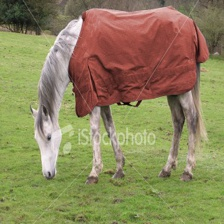

In [3]:
data_name = "infoseek"
JSON_PATH = f"/home/jeonghkim/projects/pixar/data/region_rag_vqa/{data_name}/{data_name}_retrieve_k_5_gt_interleaved_v2.jsonl"

# Load your file
# jsonl_path = "/path/to/your/file.jsonl"
data = load_jsonl(JSON_PATH)

# Visualize a specific record (e.g., the 0th)
render_record(data[801])

In [1]:
# Jupyter-ready: token-length distribution utility with a bar chart (bins of 64 from 0..2048).
# - Uses a HuggingFace tokenizer if available (tries LLaVA -> GPT-2), otherwise falls back to a simple regex tokenizer.
# - Visualizes a single bar chart (Matplotlib) with x-axis capped at 2048 and bin width 64.
# - Prints summary stats and returns a DataFrame of counts per bin.
#
# Usage:
#   JSON_PATH = "/path/to/your.jsonl"
#   print_token_stats(JSON_PATH)                # default uses answer > answer_draft > question
#   print_token_stats(JSON_PATH, field="answer_draft")
#
# If you've already defined load_jsonl in a previous cell, this will reuse it. Otherwise, a local version is provided.

import os, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import List, Dict, Any, Optional
from IPython.display import display

# ---------- Helpers ----------

def _local_load_jsonl(path: str) -> List[Dict[str, Any]]:
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError:
                pass
    return rows

# Prefer previously defined load_jsonl
if 'load_jsonl' not in globals():
    load_jsonl = _local_load_jsonl  # type: ignore

def _get_tokenizer():
    # Try LLaVA first, then GPT-2; if both unavailable (no internet/cache), fallback to regex.
    try:
        from transformers import AutoTokenizer
        for name in ["llava-hf/llava-1.5-7b-hf", "gpt2"]:
            try:
                tok = AutoTokenizer.from_pretrained(name, use_fast=True)
                return ("hf", tok)
            except Exception:
                continue
    except Exception:
        pass
    # Fallback: regex-based tokenizer
    def regex_tokenize(text: str) -> List[str]:
        if not text:
            return []
        # crude tokenization: words and punctuation
        return re.findall(r"\w+|[^\w\s]", text, flags=re.UNICODE)
    return ("regex", regex_tokenize)

_MODE, _TOKENIZER = _get_tokenizer()

def _count_tokens(text: str) -> int:
    if _MODE == "hf":
        try:
            return len(_TOKENIZER.encode(text, add_special_tokens=False))
        except Exception:
            pass
    # fallback
    return len(_TOKENIZER(text))

def _extract_text(rec: Dict[str, Any], field: Optional[str]) -> str:
    # Priority: explicit field if provided; else answer > answer_draft > question
    if field:
        return str(rec.get(field, "") or "")
    for k in ("answer", "answer_draft", "question"):
        if rec.get(k):
            return str(rec.get(k))
    # last resort: join several plausible fields
    parts = [rec.get("question", ""), rec.get("answer_draft", ""), rec.get("answer", "")]
    return " ".join([str(x) for x in parts if x])

def _bin_edges_0_2048_step_64():
    # edges for np.histogram: 0,64,128,...,2048  (inclusive upper bound handled by rightmost bin)
    return np.arange(0, 2048 + 64, 64, dtype=int)

# ---------- Main entry ----------

def print_token_stats(JSON_PATH: str, field: Optional[str] = None):
    """
    Compute token counts over a JSONL file and plot a bar chart histogram.
    - JSON_PATH: path to JSONL file
    - field: which field to tokenize; default None -> uses answer > answer_draft > question
    """
    if not os.path.exists(JSON_PATH):
        print(f"[ERROR] File not found: {JSON_PATH}")
        return

    records = load_jsonl(JSON_PATH)
    if not records:
        print(f"[WARN] No records loaded from: {JSON_PATH}")
        return

    lens = []
    overflow = 0
    for rec in records:
        txt = _extract_text(rec, field)
        n = _count_tokens(txt)
        lens.append(n)
        if n > 2048:
            overflow += 1

    lens = np.array(lens, dtype=int)
    # Clamp values > 2048 for plotting so they appear in the last bin.
    lens_clamped = np.clip(lens, 0, 2048)

    edges = _bin_edges_0_2048_step_64()
    counts, _ = np.histogram(lens_clamped, bins=edges)
    bin_lefts = edges[:-1]
    bin_rights = edges[1:]
    bin_labels = [f"{l}-{r-1}" for l, r in zip(bin_lefts, bin_rights)]
    df = pd.DataFrame({"bin": bin_labels, "count": counts})

    # Summary stats
    total = len(lens)
    mean = float(np.mean(lens)) if total else 0.0
    p50 = float(np.percentile(lens, 50)) if total else 0.0
    p90 = float(np.percentile(lens, 90)) if total else 0.0
    p95 = float(np.percentile(lens, 95)) if total else 0.0
    maxlen = int(np.max(lens)) if total else 0

    # Print stats
    print(f"Tokenizer mode: {_MODE} {'('+_TOKENIZER.name_or_path+')' if _MODE=='hf' else ''}")
    print(f"File: {JSON_PATH}")
    if field:
        print(f"Field: {field}")
    else:
        print("Field: auto (answer > answer_draft > question)")
    print(f"Records: {total} | Mean: {mean:.1f} | P50: {p50:.0f} | P90: {p90:.0f} | P95: {p95:.0f} | Max: {maxlen}")
    if overflow:
        print(f"Note: {overflow} record(s) exceeded 2048 tokens; clamped into the last bin for plotting.")

    # Plot
    plt.figure(figsize=(10, 4))
    # Centers for bars
    centers = bin_lefts + 32
    plt.bar(centers, counts, width=64, align="center")
    plt.title("Token Length Distribution (bins=64, range=0..2048)")
    plt.xlabel("Tokens")
    plt.ylabel("Count")
    plt.xlim(0, 2048)
    # Set x ticks every 256 for readability
    xticks = np.arange(0, 2048 + 1, 256)
    plt.xticks(xticks)
    plt.tight_layout()
    plt.show()

    # Show counts table
    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user("Token bins (0..2048 step 64)", df)
    except Exception:
        display(df)

    return df

print("✅ Loaded print_token_stats(). Run: print_token_stats(JSON_PATH)  # optional: field='answer_draft'")



Bad key keymap.all_axes in file /mnt/xarfuse/uid-694457/0371520c-seed-nspid4026531836_cgpid32428-ns-4026531841/bento/server/matplotlibrc-3.1.3, line 76 ('keymap.all_axes : a                 # enable all axes')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.10.3/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution


✅ Loaded print_token_stats(). Run: print_token_stats(JSON_PATH)  # optional: field='answer_draft'


findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.


findfont: Font family 'Noto Sans TC' not found.


findfont: Font family 'Noto Sans SC' not found.


findfont: Font family 'Noto Naskh Arabic UI' not found.


findfont: Font family 'Noto Sans UI' not found.


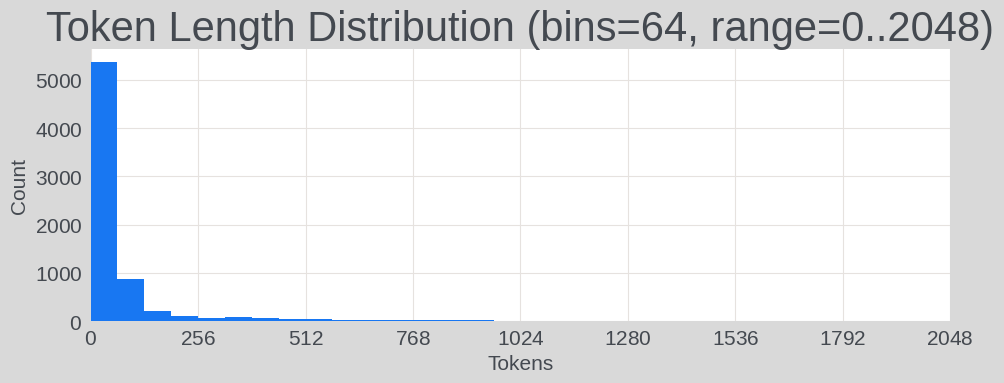

,bin,count
0,0-63,5368
1,64-127,866
2,128-191,216
3,192-255,97
4,256-319,71
5,320-383,93
6,384-447,68
7,448-511,48
8,512-575,38
9,576-639,29


,bin,count
0,0-63,5368
1,64-127,866
2,128-191,216
3,192-255,97
4,256-319,71
5,320-383,93
6,384-447,68
7,448-511,48
8,512-575,38
9,576-639,29


In [8]:
data_name = "oven"
JSON_PATH = f"/home/jeonghkim/projects/pixar/data/region_rag_vqa/{data_name}/{data_name}_retrieve_k_5_gt_interleaved_v2.jsonl"
print_token_stats(JSON_PATH)                 # default: answer > answer_draft > question
# or
# print_token_stats(JSON_PATH, field="answer_draft")